## Questuon 4

#### Environment Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

#  folder for figures
os.makedirs('../outputs/figures', exist_ok=True)



In [2]:
# Load the dataset
df = pd.read_csv(r"C:\Users\KHABAZELA\OneDrive\Desktop\ITMLA2_Project\data\smart_building_profiles.csv")

# Inspect the data
print("Dataset Shape:", df.shape)
print(df.head())



Dataset Shape: (178, 14)
  Building_ID  Avg_Indoor_Temperature_C  Daily_HVAC_Runtime_Hours  \
0     BLD-001                     18.87                     4.445   
1     BLD-002                     18.67                     4.175   
2     BLD-003                     19.17                     3.470   
3     BLD-004                     20.33                     4.475   
4     BLD-005                     19.73                     6.950   

   Occupancy_Density_per_1000m2  Heating_Setpoint_C  Monthly_Water_Use_m3  \
0                          46.0               21.35                 158.4   
1                          50.6               19.70                 187.2   
2                          44.8               19.40                 178.2   
3                          52.0               19.16                 169.2   
4                          45.6               19.55                 176.4   

   Insulation_Performance_Score  Solar_Gain_Index  Window_to_Wall_Ratio  \
0                     

In [3]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Building_ID                     0
Avg_Indoor_Temperature_C        0
Daily_HVAC_Runtime_Hours        0
Occupancy_Density_per_1000m2    0
Heating_Setpoint_C              0
Monthly_Water_Use_m3            0
Insulation_Performance_Score    0
Solar_Gain_Index                0
Window_to_Wall_Ratio            0
Equipment_Diversity_Index       0
Peak_Demand_kW                  0
Lighting_Efficiency_Index       0
Ventilation_Rate_ACH            0
Annual_Energy_Use_kWh_m2        0
dtype: int64


#### 4.1 Data Preparation and Silhouette Analysis

In [5]:
#  Exclude Building_ID and standardise
X = df.drop(columns=['Building_ID'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#  Silhouette Analysis for k = 2 to 6
silhouette_scores = []
k_values = range(2, 7) # This creates [2, 3, 4, 5, 6]

for k in k_values:
    # Fit K-Means for the current k
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    # Calculate the silhouette score
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)
    
    print(f"k = {k}: Silhouette Score = {score:.4f}")


k = 2: Silhouette Score = 0.2683
k = 3: Silhouette Score = 0.2849
k = 4: Silhouette Score = 0.2556
k = 5: Silhouette Score = 0.1778
k = 6: Silhouette Score = 0.1948


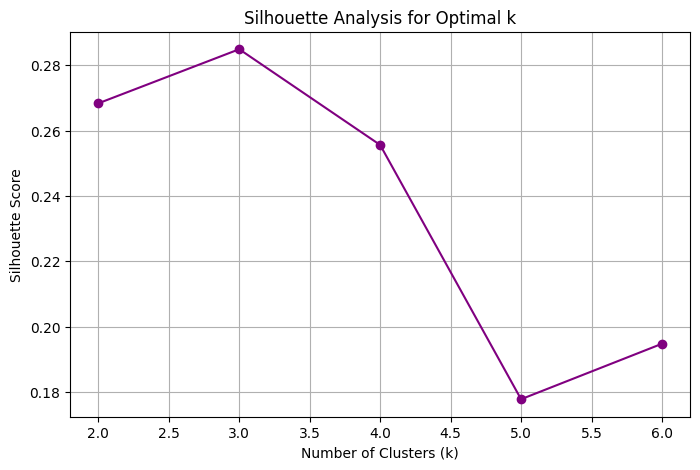

In [6]:

#  Plot the Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o', linestyle='-', color='purple')
plt.title('Silhouette Analysis for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.savefig('../outputs/figures/q4_silhouette_scores.png', dpi=300, bbox_inches='tight')
plt.show()

#### 4.2 Final K-Means Model and Counts

In [8]:
# Fit the final K-Means model with k=3
final_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = final_kmeans.fit_predict(X_scaled)

#  Report the number of buildings in each cluster
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()
print("--- Number of Buildings per Cluster ---")
for cluster_id, count in cluster_counts.items():
    print(f"Cluster {cluster_id}: {count} buildings")

--- Number of Buildings per Cluster ---
Cluster 0: 62 buildings
Cluster 1: 51 buildings
Cluster 2: 65 buildings


#### PCA and Scatter Plot

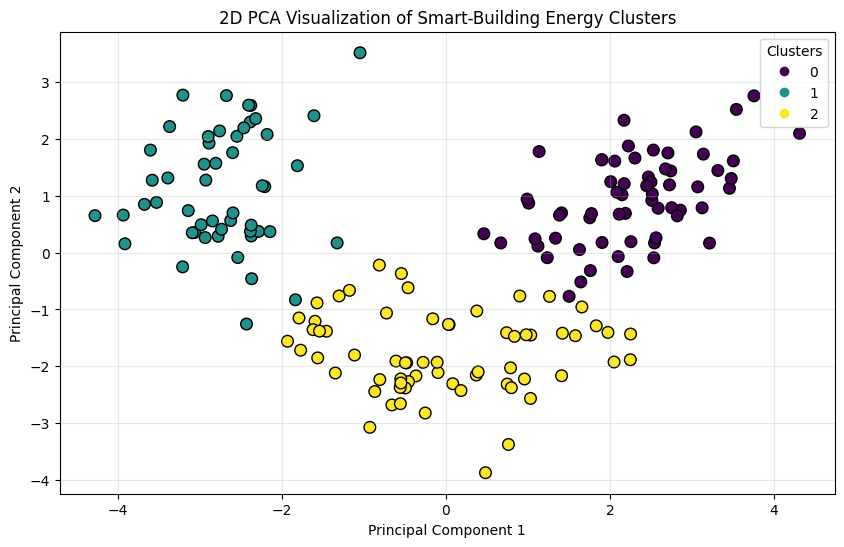

In [9]:
#  Reduce the standardised data to 2 Principal Components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

#  Create the scatter plot coloured by cluster
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', edgecolor='k', s=70)
plt.title('2D PCA Visualization of Smart-Building Energy Clusters')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, alpha=0.3)
plt.savefig('../outputs/figures/q4_pca_clusters.png', dpi=300, bbox_inches='tight')
plt.show()

#### 4.3 Cluster Profiling

In [10]:
# DataFrame with the original data and the cluster labels
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_labels

#  Drop the Building_ID for the mean calculation
df_profile = df_clustered.drop(columns=['Building_ID'])

#  Calculate the mean values for each cluster
cluster_means = df_profile.groupby('Cluster').mean().round(2)

#  the results (Transposed so it fits on the screen nicely)
print("--- Cluster Centroids (Original Measurement Units) ---")
print(cluster_means.T)

--- Cluster Centroids (Original Measurement Units) ---
Cluster                            0       1       2
Avg_Indoor_Temperature_C       20.18   19.63   18.75
Daily_HVAC_Runtime_Hours        5.00    6.96    4.85
Occupancy_Density_per_1000m2   49.33   48.35   44.62
Heating_Setpoint_C             19.24   20.37   20.02
Monthly_Water_Use_m3          194.34  177.60  166.93
Insulation_Performance_Score    6.70    4.37    5.50
Solar_Gain_Index               30.03    8.19   20.50
Window_to_Wall_Ratio            0.29    0.45    0.36
Equipment_Diversity_Index       9.61    5.73    8.12
Peak_Demand_kW                109.07  144.69   59.46
Lighting_Efficiency_Index      53.27   34.60   53.14
Ventilation_Rate_ACH            3.16    1.70    2.80
Annual_Energy_Use_kWh_m2      220.05  123.81  102.03
